# HERA demo: $V$ closure test

$V=\sum_q(q-\bar q)$, with a valence sum rule, fixed tails, and boundary continuity. The generating coefficient is $c=2$; the covariance is divided by 100 for the information projection. The fixed background and tails are inside the EFT factor.

The EFT factor is $v(c,Q^2)=1+(Q^2/\Lambda^2)c+(Q^4/\Lambda^4)c^2$, with $\Lambda=500$ GeV. We compare separate MLE, its one-step correction, and joint MLE over repeated pseudo-data draws.

The tables and figures below summarize the saved simulation results used in the paper: 1,000 replicates with 500 bootstrap draws per fit. The archived results are loaded by default; Section 6 provides an optional rerun of the inference stage.

To regenerate the tables and plots, select **Restart Kernel and Run All** from the repository directory. The saved outputs can also be read without executing the notebook. Execution requires NumPy, pandas, Matplotlib, SciPy, `paper_demo_utils.py`, and the included `paper_results/` archive. LHAPDF is not required to use the saved model. See [setup and reproduction instructions](README.md).

[1. Saved experiment](#experiment) · [2. Summary](#summary) · [3. Sampling distributions](#sampling) · [4. Coverage](#coverage) · [5. Calibration](#calibration) · [6. Optional rerun](#rerun)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display
from paper_demo_utils import load_results, make_series, summarize

paper_path = Path('paper_results/V_simulation_results_c=2_Lambda=500.npz')
paper = load_results(paper_path, expected_sha256='648f88f71fc09f8f6a5aa7353be1332c91862b6b643c832799f73bd986c5d8dc')
truth = paper["c_true"]
# Match the estimator selection and joint-MLE interval in the original plotting cells.
selection = [("separate", "plug_in"), ("separate", "one_step"), ("joint", "plug_in")]
joint_ci = "asymptotic"  # "bootstrap" is also available in the snapshot
series = make_series(paper, selection, joint_ci=joint_ci)
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})


<a id="experiment"></a>
## 1. Saved experiment

Settings are read from the archive, not inferred from notebook defaults. The full archive remains available as `paper`.

In [2]:
configuration_keys = ["notebook_file", "pdfset", "c_true", "Lambda", "N_sim",
    "simulation_seed", "n_boot_sim", "data_information_multiplier",
    "spline_degree", "n_basis", "parametrize", "enforce_sum_rule",
    "mle_constrained", "pin_endpoints", "background_inside_eft",
    "simulation_joint_mle_ci_method", "simulation_joint_mle_hessian_method"]
configuration = pd.Series({key: paper[key] for key in configuration_keys if key in paper}, name="saved value")
display(configuration.to_frame())
print(f"Snapshot: {paper_path}")
print(f"Data points: {len(paper['xQ2'])}; design matrix: {paper['design_matrix'].shape}")


,saved value
notebook_file,V_demo.ipynb
pdfset,NNPDF40_nnlo_as_01180
c_true,2
Lambda,500.0
N_sim,1000
simulation_seed,1
n_boot_sim,500
data_information_multiplier,100
spline_degree,3
n_basis,8


Snapshot: paper_results/V_simulation_results_c=2_Lambda=500.npz
Data points: 67; design matrix: (67, 6)


The V archive does not record the Hessian method used for its saved joint-MLE interval. The saved intervals are displayed directly; optional reruns explicitly use the numerical Hessian.

<a id="summary"></a>
## 2. Estimation and interval summary

Coverage and interval widths include replicates with finite estimates, standard errors, and interval endpoints. The table reports the denominators so missing results are visible. Separate-MLE intervals use bootstrap; joint-MLE intervals use the selected method above. One-step intervals are analytical normal intervals.

In [3]:
summary = summarize(paper, series)
display(summary.round(4))


,interval,valid_estimates,valid_intervals,total,mean,bias,std,coverage,mean_width
estimator,,,,,,,,,
separate MLE,bootstrap,1000,1000,1000,0.5800,-1.4200,0.0410,0.000,0.1645
separate one-step,one_step,1000,1000,1000,1.9860,-0.0140,0.1695,0.948,0.6796
joint MLE,asymptotic,1000,1000,1000,1.9746,-0.0254,0.1545,0.962,0.6437


<a id="sampling"></a>
## 3. Sampling distributions

Histograms include all finite estimates for each selected estimator. The dashed lines mark the generating coefficient and the Standard Model value.

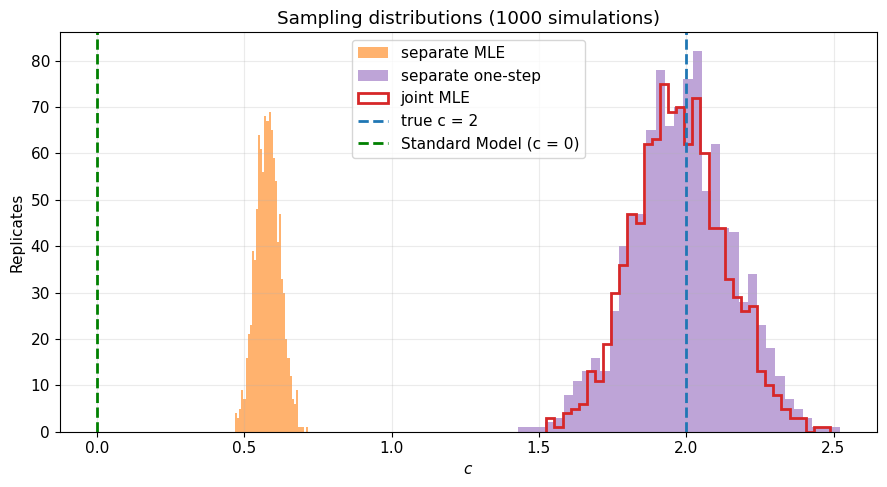

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for s in series:
    values = s["estimates"][np.isfinite(s["estimates"])]
    style = dict(histtype="step", linewidth=2) if s["method"] == "joint" else dict(alpha=0.6)
    ax.hist(values, bins=35, color=s["color"], label=s["label"], **style)
ax.axvline(truth, color="C0", ls="--", lw=2, label=f"true c = {truth:g}")
ax.axvline(0, color="green", ls="--", lw=2, label="Standard Model (c = 0)")
ax.set(xlabel="$c$", ylabel="Replicates", title=f"Sampling distributions ({paper['N_sim']} simulations)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


<a id="coverage"></a>
## 4. Coverage and interval widths

These use the saved 95% interval endpoints directly. The horizontal line marks nominal 95% coverage.

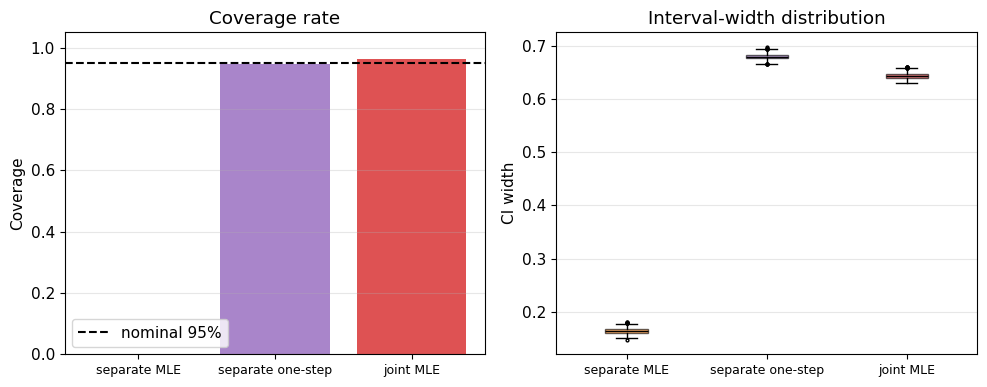

In [5]:
valid_series = [s for s in series if np.any(s["valid"])]
if not valid_series:
    raise ValueError("No finite intervals for the selected estimators")
labels = [s["label"] for s in valid_series]
intervals = [s["cis"][s["valid"]] for s in valid_series]
coverages = [np.mean((ci[:, 0] <= truth) & (ci[:, 1] >= truth)) for ci in intervals]
widths = [ci[:, 1] - ci[:, 0] for ci in intervals]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(labels, coverages, color=[s["color"] for s in valid_series], alpha=0.8)
axes[0].axhline(0.95, color="black", ls="--", label="nominal 95%")
axes[0].set(ylabel="Coverage", ylim=(0, 1.05), title="Coverage rate")
axes[0].legend()
boxes = axes[1].boxplot(widths, tick_labels=labels, patch_artist=True,
    medianprops=dict(color="black"), flierprops=dict(marker=".", markersize=4))
for box, s in zip(boxes["boxes"], valid_series):
    box.set(facecolor=s["color"], alpha=0.6)
axes[1].set(ylabel="CI width", title="Interval-width distribution")
for ax in axes:
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


<a id="calibration"></a>
## 5. Coverage calibration

Each curve uses normal intervals $\hat c \pm z_{1-\alpha/2}\,\widehat{\mathrm{SE}}$ built from saved standard errors. For bootstrap series this is a normal approximation using bootstrap standard deviations, not a new percentile-bootstrap calculation at each level.

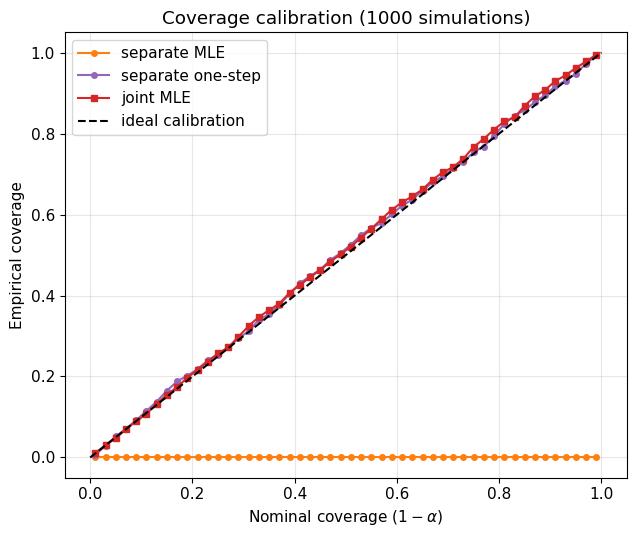

In [6]:
nominal_levels = 1 - np.linspace(0.01, 0.99, 50)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for s in valid_series:
    estimates, ses = s["estimates"][s["valid"]], s["ses"][s["valid"]]
    empirical = []
    for level in nominal_levels:
        z = norm.ppf((1 + level) / 2)
        empirical.append(np.mean((estimates - z*ses <= truth) & (estimates + z*ses >= truth)))
    ax.plot(nominal_levels, empirical, color=s["color"],
            marker="s" if s["method"] == "joint" else "o", ms=4, label=s["label"])
ax.plot([0, 1], [0, 1], "k--", label="ideal calibration")
ax.set(xlabel=r"Nominal coverage $(1-\alpha)$", ylabel="Empirical coverage",
       title=f"Coverage calibration ({paper['N_sim']} simulations)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


<a id="rerun"></a>
## 6. Optional reproduction from the saved model

Set `run_reproduction=True` for a small rerun. The helper refits the **archived design matrix, covariance, generating mean, EFT kernels, offsets, and constraints**, using the repository's current `utils.py`. It does not regenerate FK tables or integrate LHAPDF; the original research notebook documents those steps.

The default rerun is 10 replicates without bootstrap. To use the paper's sample counts, set `rerun_count=int(paper["N_sim"])` and `rerun_bootstrap_count=int(paper["n_boot_sim"])`; this can take a long time. New results are separate from `paper`, and saving creates a unique file under `simulation_results/paper_reruns/`.

Exact historical numerical reproduction is not guaranteed: optimizer/library versions and random initialization matter, and the historical HERA bootstrap calls did not set a seed. The saved paper snapshot is the authoritative source for the figures above. A seed is explicit for new data and bootstrap draws. Numerical Hessians are explicit for new joint-MLE intervals.

In [8]:
run_reproduction = False
rerun_count = 10
rerun_bootstrap_count = 0
rerun_seed = int(paper["simulation_seed"])
save_new_results = False

if run_reproduction:
    from paper_demo_utils import rerun, save_rerun
    new_results = rerun(paper, n_sim=rerun_count, n_boot=rerun_bootstrap_count,
                        seed=rerun_seed, hessian_method="numerical")
    new_series = make_series(new_results, selection, joint_ci="asymptotic")
    display(summarize(new_results, new_series).round(4))
    if save_new_results:
        print("Saved new results:", save_rerun(new_results, 'V'))
else:
    print("Paper results displayed; optional reproduction is disabled.")


Paper results displayed; optional reproduction is disabled.
